# GLP-1 계열 의약품의 이상사례 신고는 언제, 무엇으로 구분되는가?
**빅데이터시각화 PBL · 코랩 CPU 실습 · 신고 단위 통계·머신러닝·설명**

**실행 방법**　코랩에서 이 노트북을 열고 ‘런타임 → 모두 실행’을 선택한다. 업로드 창에는 팀이 공유한 **OneDrive 원본 ZIP**을 넣는다. 파일 탭에 이미 올렸다면 첫 셀의 `INPUT_PATH`를 지정한다. 원본 XLSX·CSV와 기존 `glp1_preprocessing.zip`도 지원한다. 결과 예시는 노트북에 저장되어 있다. 외부 모델, GPU, 추가 다운로드가 필요 없다.

| CRISP-DM | 수업에서 할 일 | 산출물 |
|---|---|---|
| 업무 이해 | 어느 시점에 어떤 정보가 들어오는지 결정한다 | 기본정보 모델과 코딩 완료 모델의 사용 범위 |
| 데이터 이해·준비 | 같은 신고의 여러 반응을 분리하고 시간·결측·라벨을 감사한다 | 신고표·반응표·학생 파일 대조표·제외 내역 |
| EDA | 서연은 약물·기간·국가, 수연은 환자 특성·반응·중대 비율을 분석한다 | 분모와 95% 구간을 붙인 표, 필터형 대시보드 |
| 모델링 | 시간순으로 여러 모델을 비교하고 검증자료에서 기준을 고정한다 | 후보 점수표·선정 기록·분류 임계값 |
| 평가·활용 | 시험 성능, 오류, 확률 보정, 하위 집단, 예측 근거를 읽는다 | 평가표·XAI·팀별 후속 연구 질문 |

**질문**　기록된 중대 신고 표식을 얼마나 잘 구분할 수 있을까? 환자에게 앞으로 일어날 이상반응을 예측하는 설계와는 시간 기준·분모가 다르다. 이상사례 보고에는 투약자 전체 수, 보고되지 않은 사례, 독립적인 인과성 판정이 없다. 약물별 신고 수·중대 신고 비율은 **수집된 신고 안에서** 해석한다. 완성된 신고 파일에는 각 항목의 입력 시각도 없어 실시간 접수 성능을 확인할 수 없다.

자료 설명 · [Kaggle 원자료](https://www.kaggle.com/datasets/devtayyabsajjad/glp-1-weight-loss-drugs-master-dataset-2017-2026) · [FDA 보고자료 개요](https://open.fda.gov/apis/drug/event/) · [FDA 필드 정의](https://open.fda.gov/fields/drugevent_reference.pdf) · [FDA 공식 해석상 주의점](https://www.fda.gov/media/165667/download)


In [1]:
from pathlib import Path
from zipfile import ZipFile
from collections import Counter
from itertools import combinations
from math import factorial
import hashlib, html, io, json, platform, re, shutil, tempfile, time, warnings
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator
from IPython.display import display, Image
from scipy import sparse
from scipy.special import logit
from scipy.stats import chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MultiLabelBinarizer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
    roc_curve, brier_score_loss, confusion_matrix, f1_score, precision_score, recall_score)
from threadpoolctl import threadpool_limits

INPUT_PATH = ""     # 예: "/content/OneDrive_2026-11-13.zip" 또는 "/content/adverse_events.csv"
AUTO_DOWNLOAD = False
SEED, THREADS = 42, 2
START = time.monotonic()
ROOT = Path("/content") if Path("/content").is_dir() else Path.cwd()
OUT = Path(tempfile.mkdtemp(prefix="GLP1_PBL_", dir=ROOT))
FIG, TAB, DATA = [OUT/x for x in ["figures","tables","clean_data"]]
for folder in [FIG,TAB,DATA]:
    folder.mkdir()


### 그림 수정 | 이 셀에서 색·폰트·크기를 바꾸고 원하는 그림 셀만 다시 실행한다
600 dpi PNG는 제출용, PDF·SVG는 벡터 편집용이다. 각 그림 셀에서 제목·축 이름·표시 항목을 변경할 수 있다. 기본 영문 축은 코랩의 한글 폰트 설치 여부에 영향을 받지 않는다.


In [2]:
DPI, WIDTH, SIZE = 600, 8.2, 9
FONT = "DejaVu Sans"    # Arial 설치 환경에서는 "Arial" 사용 가능
COL = {"base":"#287271","coded":"#B35439","neutral":"#63778A","pale":"#C1DCD7","ink":"#243642"}
assert DPI>=600
mpl.rcParams.update({"font.family":FONT,"font.size":SIZE,"axes.titlesize":SIZE+1,"axes.titleweight":"bold",
 "axes.spines.top":False,"axes.spines.right":False,"axes.linewidth":.7,"axes.edgecolor":COL["ink"],
 "text.color":COL["ink"],"pdf.fonttype":42,"svg.fonttype":"none","savefig.facecolor":"white"})
def figure(r=1,c=1,height=3.4):
    return plt.subplots(r,c,figsize=(WIDTH,height),layout="constrained")
def title(ax,letter,name):
    ax.set_title(f"{letter}   {name}",loc="left",pad=7)
def finish(fig,name):
    for ext in ("png","pdf","svg"):
        fig.savefig(FIG/f"{name}.{ext}",dpi=DPI,bbox_inches="tight",pad_inches=.08)
    buf=io.BytesIO()
    fig.savefig(buf,format="png",dpi=118,bbox_inches="tight")
    display(Image(data=buf.getvalue()))
    plt.close(fig)
def write(frame,name,n=0):
    frame.to_csv(TAB/f"{name}.csv",index=False,encoding="utf-8-sig")
    if n:
        display(frame.head(n).round(4))


## 1 · 입력 확인 | 원자료, 학생 전처리, 기존 모델의 역할
OneDrive ZIP에서는 원본 엑셀을 다시 읽는다. 함께 들어 있는 학생 신고표와 기분할 ID는 **대조용**이다. 원자료 대신 전처리 ZIP만 주면 그 안의 반응 단위 파일에 남아 있는 원본 16개 열에서 시작한다. 이 경우 기존 전처리에서 이미 빠진 원본 행은 확인할 수 없다. 입력 경로와 SHA-256을 재현 기록에 남긴다. 기존 학생 노트북에서 약물명 제외 랜덤포레스트의 시험 ROC-AUC는 0.6524, F1은 0.4447이었다. 마지막 평가표에 이 수치를 별도 출처로 병기한다.


In [3]:
def locate():
    if INPUT_PATH:
        return Path(INPUT_PATH).expanduser()
    for name in ["OneDrive_2026-11-13.zip","adverse_events.csv","glp1_preprocessing.zip"]:
        if (ROOT/name).is_file():
            return ROOT/name
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("INPUT_PATH에 원자료 또는 OneDrive ZIP 경로를 입력하세요.")
    uploaded=files.upload()
    if len(uploaded)!=1:
        raise ValueError("한 번에 원본 ZIP, XLSX 또는 CSV 한 개를 선택하세요.")
    return Path(next(iter(uploaded)))

def from_student_archive(archive):
    lookup={Path(n).name:n for n in archive.namelist()}
    reference={}
    for k in ["report_level","reaction_level","train","validation","test"]:
        name=f"glp1_{k}.csv"
        if name in lookup:
            reference[k]=pd.read_csv(archive.open(lookup[name]),dtype={"safetyreportid":str})
    return reference

path=locate()
student={}
input_mode=path.suffix.lower()
if input_mode==".zip":
    with ZipFile(path) as z:
        names=z.namelist()
        originals=[n for n in names if Path(n).name.lower().startswith("adverse_events") and n.lower().endswith((".xlsx",".csv"))]
        nested=[n for n in names if Path(n).name=="glp1_preprocessing.zip"]
        if nested:
            with ZipFile(io.BytesIO(z.read(nested[0]))) as inner:
                student=from_student_archive(inner)
        if len(originals)==1:
            member=originals[0]
            payload=io.BytesIO(z.read(member))
            raw=(pd.read_excel(payload,dtype=str,keep_default_na=False) if member.lower().endswith(".xlsx")
                 else pd.read_csv(payload,dtype=str,keep_default_na=False))
            input_mode="archived original"
        elif not originals:
            if not student:
                student=from_student_archive(z)
            if "reaction_level" not in student:
                raise ValueError("원본 adverse_events 파일 또는 반응 단위 파일이 필요합니다.")
            raw=student["reaction_level"].copy()
            input_mode="student reaction export"
        else:
            raise ValueError("원본이 여러 개입니다. 사용할 파일 한 개를 지정하세요.")
elif input_mode==".xlsx":
    raw=pd.read_excel(path,dtype=str,keep_default_na=False)
elif input_mode==".csv":
    raw=pd.read_csv(path,dtype=str,keep_default_na=False)
else:
    raise ValueError("지원 형식: ZIP, XLSX, CSV")
raw.columns=raw.columns.str.strip().str.lower()
ID="safetyreportid"
FLAGS=["seriousness_death","seriousness_lifethreatening","seriousness_hospitalization","seriousness_disabling"]
required=[ID,"generic_name","brand_queried","receive_date","country","serious",*FLAGS,"patient_age",
          "patient_age_unit","patient_sex","patient_weight_kg","reaction","reaction_outcome"]
if not set(required)<=set(raw):
    raise ValueError(f"누락 열: {set(required)-set(raw)}")
raw=raw[required].copy()
print(f"입력 유형 {input_mode} · {len(raw):,}행 · {len(raw.columns)}열")


Saving adverse_events.xlsx to adverse_events.xlsx
입력 유형 .xlsx · 149,209행 · 16열


## 2 · 전처리 | 신고 한 건을 몇 번 셀 것인가?
**규칙 ①** 중대성은 원래의 `serious`만 목표로 쓴다. 결과 플래그로 라벨을 만들어 채우지 않는다. 필수 ID·라벨이 없거나 같은 ID에 라벨이 충돌하면 해당 행 또는 해당 ID를 격리한다. 날짜 미상은 EDA에 남기고 시간 평가에서 제외한다. 같은 ID 안에서 불일치하는 기본속성은 결측으로 남긴다.

이번 자료에서는 중대 신고 7,957건에 제공된 네 가지 중대성 플래그가 모두 꺼져 있다. 이 네 열을 OR로 합쳐 목표를 다시 만들면 이 신고들의 라벨이 바뀐다.

**규칙 ②** 나이를 연 단위로 통일한다. 0세 표기는 보존한다. 체중은 원본 kg를 그대로 읽고, 0 이하 또는 500kg 초과를 검토 대상으로 분리해 주 분석에서 결측 처리한다. 이 상한은 자료 오류를 찾기 위한 분석 규칙이다. 2kg 미만도 일괄 삭제하지 않으며, 검토표로 남긴다. 수치 대치, 범주 인코딩, 반응 어휘 선택은 나중에 학습 데이터에만 적합한다.

**규칙 ③** 신고 수는 고유 신고 ID, 반응 빈도는 고유 **신고 ID × 정규화한 반응명**으로 집계한다. 같은 사람의 재신고는 환자 연계키가 없어 연결할 수 없다.


In [4]:
def clean_str(s):
    return s.astype("string").str.normalize("NFKC").str.strip().str.replace(r"\s+"," ",regex=True).replace("",pd.NA)
def flag(s):
    return clean_str(s).str.lower().map({"true":1,"false":0,"1":1,"0":0,"1.0":1,"0.0":0})
def dump_data(df,name):
    df.to_csv(DATA/f"{name}.csv.gz",index=False,compression="gzip")
w=raw.copy()
w[ID]=clean_str(w[ID]).replace({"Unknown":pd.NA,"UNK":pd.NA}).str.replace(r"^(\d+)\.0$",r"\1",regex=True)
w["y"]=flag(w.serious)
invalid=w[ID].isna()|w.y.isna()
valid=w.loc[~invalid].copy()
conflict=valid.groupby(ID).y.nunique()
bad_ids=conflict.index[conflict.gt(1)]
reject=w.loc[invalid|w[ID].isin(bad_ids),[ID,"serious"]].copy()
reject["reason"]=np.where(reject[ID].isin(bad_ids),"conflicting target","missing ID or invalid target")
dump_data(reject,"excluded_input")
w=valid[~valid[ID].isin(bad_ids)].copy()
w["y"]=w.y.astype(int)
for field in FLAGS:
    w[field]=flag(w[field])
w["date"]=pd.to_datetime(clean_str(w.receive_date),format="mixed",errors="coerce").dt.normalize()
w["drug"]=clean_str(w.generic_name).str.lower().replace({"unknown":pd.NA})
w["brand"]=clean_str(w.brand_queried).str.upper().replace({"UNKNOWN":pd.NA,"UNK":pd.NA})
w["nation"]=clean_str(w.country).str.upper().replace({"UNKNOWN":pd.NA,"UNK":pd.NA})
w["sex"]=clean_str(w.patient_sex).str.title().replace({"Unknown":pd.NA,"Unk":pd.NA})
unit_map={"year":1,"years":1,"decade":10,"month":1/12,"week":7/365.25,"day":1/365.25,"hour":1/(24*365.25)}
age_num=pd.to_numeric(w.patient_age,errors="coerce")
age=age_num*clean_str(w.patient_age_unit).str.lower().map(unit_map)
weight=pd.to_numeric(w.patient_weight_kg,errors="coerce")
w["age"]=age.where(age.between(0,120))
w["weight"]=weight.where(weight.gt(0)&weight.le(500))
w["term"]=clean_str(w.reaction).str.casefold().replace({"unknown":pd.NA})
review=w.loc[weight.notna()&(~weight.between(2,500))|age_num.notna()&w.age.isna(),
             [ID,"patient_age","patient_age_unit","patient_weight_kg"]].drop_duplicates()
write(review,"01_numeric_review")
attributes=["drug","brand","nation","sex","date","age","weight"]
g=w.groupby(ID,sort=False)
reps=g[["y",*attributes,*FLAGS]].first()
conflicts=g[attributes].nunique(dropna=True)>1
reps[attributes]=reps[attributes].mask(conflicts)
write(conflicts.loc[conflicts.any(axis=1)].reset_index(),"01_attribute_conflicts")
for col in ["drug","brand","nation","sex"]:
    reps[col]=reps[col].fillna("Unknown")
rx=w[[ID,"term"]].dropna().drop_duplicates().copy()
term_lists=rx.groupby(ID,sort=False).term.agg(tuple)
reps["terms"]=[x if isinstance(x,tuple) else () for x in term_lists.reindex(reps.index).to_list()]
reps["n_terms"]=reps.terms.map(len)
reps=reps.reset_index().sort_values(["date",ID],na_position="last").reset_index(drop=True)
assert reps[ID].is_unique and not rx.duplicated().any() and set(rx[ID])<=set(reps[ID])
reps["year"]=reps.date.dt.year.astype("Int64")
reps["age_group"]=pd.cut(reps.age,[-np.inf,18,35,50,65,75,np.inf],right=False,
    labels=["<18","18–34","35–49","50–64","65–74","75+"]).astype("string").fillna("Unknown")
reps["age_missing"]=reps.age.isna().astype(int)
reps["weight_missing"]=reps.weight.isna().astype(int)
qc=pd.DataFrame([dict(raw_rows=len(raw),exact_duplicate_rows=int(raw.duplicated().sum()),invalid_rows=int(invalid.sum()),
 conflicting_label_ids=len(bad_ids),attribute_conflict_ids=int(conflicts.any(axis=1).sum()),reports=len(reps),
 serious_reports=int(reps.y.sum()),term_pairs=len(rx),distinct_terms=rx.term.nunique(),undated=int(reps.date.isna().sum()),
 unknown_age=int(reps.age.isna().sum()),unknown_weight=int(reps.weight.isna().sum()),
 false_with_any_true_flag=int(((reps.y==0)&(reps[FLAGS].eq(1).any(axis=1))).sum()),
 serious_without_listed_flag=int(((reps.y==1)&~(reps[FLAGS].eq(1).any(axis=1))).sum()))])
write(qc,"01_quality",1)
# 기존 학생 전처리 파일과 같은 ID를 기준으로 수치 열을 비교한다.
checks=[]
if "report_level" in student:
    old=student["report_level"].set_index(ID)
    checks.append(dict(check="ID symmetric difference",different=len(set(reps[ID])^set(old.index))))
    paired=reps.set_index(ID).join(old[["serious","age_years","weight_kg_clean"]],how="inner")
    for a,b in [("y","serious"),("age","age_years"),("weight","weight_kg_clean")]:
        diff=~np.isclose(paired[a].astype(float),paired[b].astype(float),equal_nan=True)
        checks.append(dict(check=a,different=int(diff.sum())))
        if diff.any():
            write(paired.loc[diff,[a,b]].reset_index(),f"01_difference_{a}")
write(pd.DataFrame(checks,columns=["check","different"]),"01_student_preparation_check",10)
dump_data(reps.drop(columns="terms"),"glp1_report_level")
dump_data(rx,"glp1_reaction_level")


,raw_rows,exact_duplicate_rows,invalid_rows,conflicting_label_ids,attribute_conflict_ids,reports,serious_reports,term_pairs,distinct_terms,undated,unknown_age,unknown_weight,false_with_any_true_flag,serious_without_listed_flag
0,149209,0,0,0,0,54170,15502,149209,4604,0,23178,43988,0,7957


,check,different


## 3 · EDA | 보고량과 신고 내 비율을 나란히 본다
**서연**은 성분별 고유 신고 건수, 연도별 추이, 성분×연도 히트맵, 국가별 건수를 비교한다. **수연**은 성분·성별·연령대별 중대 신고 수와 비율, 상위 15개 반응의 신고 수와 중대 비율을 비교한다. 반응의 비율은 ‘그 반응을 포함한 신고 중 중대 표식이 붙은 비율’이다. 하나의 신고가 여러 반응에 들어갈 수 있다. Wilson 95% 구간은 해당 표본 내 비율의 불확실성을 요약한다. 표본 추출·보고 편향은 구간에 반영되지 않는다.


In [5]:
def rate_table(frame,keys):
    t=frame.groupby(keys,dropna=False,observed=True).y.agg(n="size",serious="sum").reset_index()
    n=t.n.to_numpy(); p=t.serious/n; z=1.959964
    mid=(p+z*z/(2*n))/(1+z*z/n)
    width=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/(1+z*z/n)
    return t.assign(rate=p,low=(mid-width).clip(0,1),high=(mid+width).clip(0,1)).sort_values("n",ascending=False)
drug=rate_table(reps,"drug"); annual=rate_table(reps.dropna(subset=["date"]),"year").sort_values("year")
nation=rate_table(reps,"nation"); age_sex=rate_table(reps,["age_group","sex"])
drug_year=rate_table(reps.dropna(subset=["date"]),["year","drug"])
reaction=rate_table(rx.merge(reps[[ID,"y"]],on=ID,validate="many_to_one"),"term")
reaction["report_share"]=reaction.n/len(reps)
for name,tab in {"drug":drug,"year":annual,"year_drug":drug_year,"country":nation,"age_sex":age_sex,
 "age":rate_table(reps,"age_group"),"sex":rate_table(reps,"sex"),"reaction":reaction,
 "brand_query":rate_table(reps,"brand"),"missing":rate_table(reps,["age_missing","weight_missing"])}.items():
    write(tab,"02_"+name)
display(drug.round(3));display(reaction.head(15).round(3))
# 신고 단위의 성별×라벨 교차표. 미상은 결측 패턴 표에서 해석한다.
xt=pd.crosstab(reps.loc[reps.sex!="Unknown","sex"],reps.loc[reps.sex!="Unknown","y"])
if min(xt.shape)>=2:
    chi,pval,df_chi,expected=chi2_contingency(xt,correction=False)
    write(pd.DataFrame([dict(n=xt.to_numpy().sum(),chi2=chi,df=df_chi,p=pval,
          cramers_v=np.sqrt(chi/(xt.to_numpy().sum()*min(xt.shape[0]-1,xt.shape[1]-1))),
          min_expected=expected.min())]),"02_sex_association",1)


,drug,n,serious,rate,low,high
5,semaglutide,14992,6204,0.414,0.406,0.422
3,liraglutide,9978,4388,0.440,0.430,0.450
6,tirzepatide,9969,655,0.066,0.061,0.071
2,exenatide,9236,2880,0.312,0.302,0.321
1,dulaglutide,4994,1053,0.211,0.200,0.222
0,albiglutide,4982,319,0.064,0.058,0.071
4,lixisenatide,19,3,0.158,0.055,0.376


,term,n,serious,rate,low,high,report_share
2876,nausea,7629,1782,0.234,0.224,0.243,0.141
4539,vomiting,3661,1419,0.388,0.372,0.403,0.068
533,blood glucose increased,3373,601,0.178,0.166,0.191,0.062
1155,diarrhoea,3156,999,0.317,0.301,0.333,0.058
2155,incorrect dose administered,3068,113,0.037,0.031,0.044,0.057
2261,injection site pain,2984,164,0.055,0.047,0.064,0.055
1125,device use error,2722,55,0.020,0.016,0.026,0.050
4561,weight decreased,2556,723,0.283,0.266,0.301,0.047
3014,off label use,2450,526,0.215,0.199,0.231,0.045
1048,decreased appetite,2065,535,0.259,0.241,0.278,0.038


,n,chi2,df,p,cramers_v,min_expected
0,50941,388.8777,1,0.0,0.0874,4756.7162


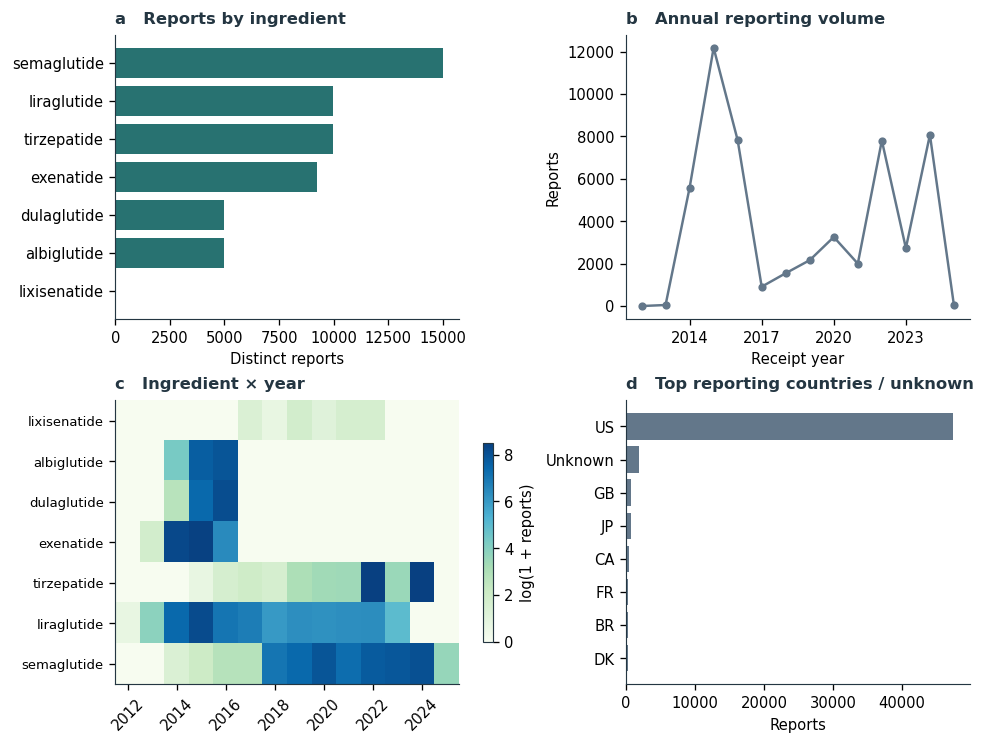

In [6]:
fig,axes=figure(2,2,6.2)
ax,bx,cx,dx=axes.flat
d=drug.sort_values("n");ax.barh(d.drug,d.n,color=COL["base"]);ax.set_xlabel("Distinct reports")
title(ax,"a","Reports by ingredient")
bx.plot(annual.year.astype(int),annual.n,"o-",ms=4,color=COL["neutral"])
bx.set(xlabel="Receipt year",ylabel="Reports");bx.xaxis.set_major_locator(MaxNLocator(5,integer=True))
title(bx,"b","Annual reporting volume")
grid=drug_year.pivot(index="drug",columns="year",values="n").fillna(0).reindex(d.drug)
im=cx.imshow(np.log1p(grid),aspect="auto",cmap="GnBu")
cx.set_yticks(range(len(grid)),grid.index,fontsize=8)
cx.set_xticks(range(0,len(grid.columns),2),grid.columns[::2],rotation=45)
fig.colorbar(im,ax=cx,shrink=.7,label="log(1 + reports)");title(cx,"c","Ingredient × year")
n=nation.head(8).sort_values("n");dx.barh(n.nation,n.n,color=COL["neutral"])
dx.set_xlabel("Reports");title(dx,"d","Top reporting countries / unknown")
finish(fig,"Fig01_reporting")


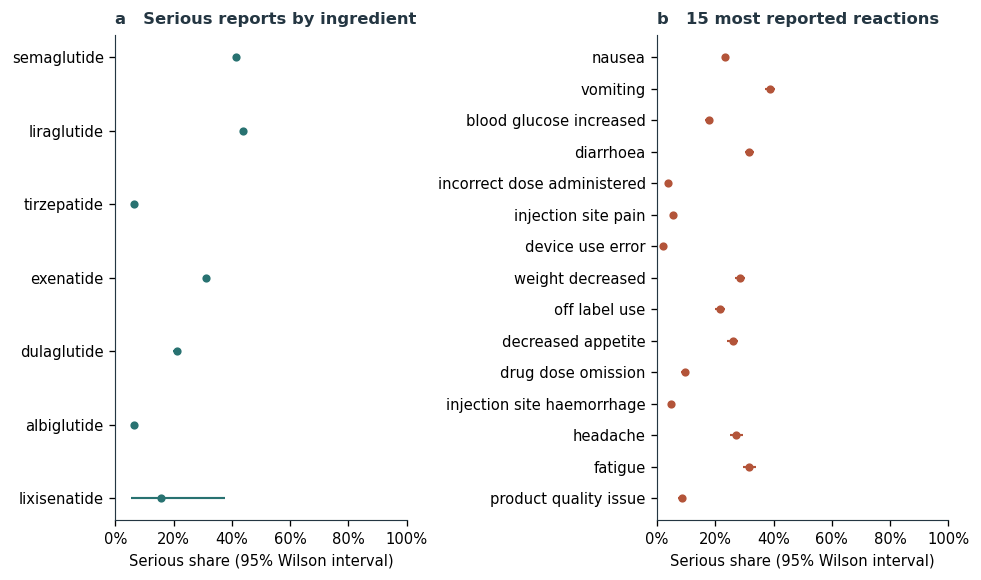

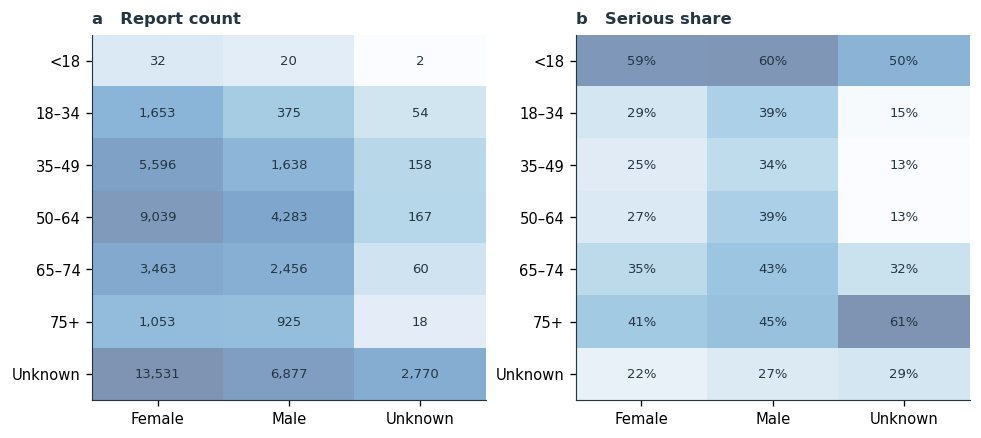

In [7]:
def intervals_plot(ax,t,field,color):
    t=t.iloc[::-1]
    ax.hlines(t[field],t.low,t.high,color=color,lw=1.3)
    ax.plot(t.rate,t[field],"o",ms=4,color=color)
    ax.set(xlim=(0,1),xlabel="Serious share (95% Wilson interval)")
    ax.xaxis.set_major_formatter(PercentFormatter(1,decimals=0))
fig,(ax,bx)=figure(1,2,4.8)
intervals_plot(ax,drug,"drug",COL["base"]);title(ax,"a","Serious reports by ingredient")
intervals_plot(bx,reaction.head(15),"term",COL["coded"]);title(bx,"b","15 most reported reactions")
finish(fig,"Fig02_serious_shares")
fig,(ax,bx)=figure(1,2,3.6)
ages=["<18","18–34","35–49","50–64","65–74","75+","Unknown"]
sexes=sorted(reps.sex.unique())
for axis,key,heading,letter in [(ax,"n","Report count","a"),(bx,"rate","Serious share","b")]:
    grid=age_sex.pivot(index="age_group",columns="sex",values=key).reindex(index=ages,columns=sexes)
    values=grid.to_numpy(dtype=float)
    axis.imshow(np.log1p(values) if key=="n" else values,cmap="Blues",aspect="auto",alpha=.52)
    for (i,j),v in np.ndenumerate(values):
        label="—" if not np.isfinite(v) else (f"{v:,.0f}" if key=="n" else f"{v:.0%}")
        axis.text(j,i,label,ha="center",va="center",fontsize=8)
    axis.set_xticks(range(len(sexes)),sexes);axis.set_yticks(range(len(ages)),ages);title(axis,letter,heading)
finish(fig,"Fig03_demographics")


## 4 · 모델 설계 | 접수 기본정보와 사후 코딩을 나누어 평가한다
- **A · 기본정보**　성분·국가·성별·나이·체중·결측 표지·접수 날짜로 신고의 중대 표식을 분류한다. 보고 시점에 실제로 확보됐는지는 별도 로그가 있어야 검증할 수 있다.
- **B · 코딩 완료**　A에 정규화한 반응명 목록과 사용 가능한 반응 수를 더한다. 신고 내용이 코딩된 뒤 활용할 수 있는 **회고적 분류**다. 사망·입원·장애·선천성 등 결과 정의를 직접 드러내는 표현도 보수적으로 제거한다. 남은 진단·증상과 중대성의 연관성, 코딩 과정의 간접 영향은 여전히 존재할 수 있다.
- **공통 제외**　ID, 조회 브랜드, 원래 중대성, 사망·생명 위협·입원·장애 플래그와 reaction_outcome을 입력에서 제외한다. 조회 브랜드는 약물 노출을 독립적으로 입증하는 필드가 아니다. 날짜·약물·국가에 대한 의존은 XAI와 집단별 성능에서 점검한다.

**시간 순서**　학생 파일과 동일한 경계를 사용한다. 2022-07-14까지 학습, 2023-12-29까지 검증, 이후 시험이다. 검증 기간의 앞·뒤 전체 날짜 묶음을 약 절반씩 나누어 앞부분에서 후보를 선택하고, 뒷부분에서 확률 보정과 F1 임계값을 정한다. 시험 기간의 모델·집단 비교는 동결된 설정으로 한 번 평가한다. 기존 팀이 이미 본 시험 기간이어서 독립적인 외부 검증은 후속 과제다.


In [8]:
OUTCOME_PATTERN=r"\b(death|deaths|dead|fatal\w*|hospitali[sz]\w*|disabil\w*|disabling|incapacit\w*|congenital|stillbirth|life[- ]threat\w*|intensive care|resuscitat\w*)\b"
proxy=re.compile(OUTCOME_PATTERN,re.I)
blocked=rx.loc[rx.term.map(lambda x:bool(proxy.search(x))),"term"]
write(blocked.value_counts().rename_axis("excluded_term").reset_index(name="report_pairs"),"03_excluded_proxy_terms")
reps["safe_terms"]=reps.terms.map(lambda v:tuple(t for t in v if not proxy.search(t)))
reps["n_safe"]=reps.safe_terms.map(len)
reps["quarter"]=reps.date.dt.to_period("Q").astype("string")
mdl=reps.dropna(subset=["date"]).copy().reset_index(drop=True)
split=np.select([mdl.date<=pd.Timestamp("2022-07-14"),mdl.date<=pd.Timestamp("2023-12-29")],
                ["train","validation"],default="test")
mdl["split"]=split
train=np.flatnonzero(split=="train"); valid=np.flatnonzero(split=="validation"); test=np.flatnonzero(split=="test")
assert min(map(len,[train,valid,test]))>0, "이 과제의 시간 분할에 맞는 원자료가 필요합니다."
cut=mdl.date.iloc[valid[len(valid)//2]]
select=valid[mdl.date.iloc[valid].lt(cut).to_numpy()]
cal=valid[mdl.date.iloc[valid].ge(cut).to_numpy()]
assert all(mdl.y.iloc[k].nunique()==2 for k in [train,select,cal,test])
assert max(mdl.date.iloc[train])<min(mdl.date.iloc[select])<=max(mdl.date.iloc[select])<min(mdl.date.iloc[cal])<=max(mdl.date.iloc[cal])<min(mdl.date.iloc[test])
split_audit=[]
for name,ids in [("Train",train),("Validation: select",select),("Validation: calibrate",cal),("Test",test)]:
    s=mdl.iloc[ids];split_audit.append(dict(split=name,n=len(s),positives=int(s.y.sum()),rate=s.y.mean(),
        first=s.date.min().date(),last=s.date.max().date(),ingredients=s.drug.nunique()))
if all(k in student for k in ["train","validation","test"]):
    for k,ids in [("train",train),("validation",valid),("test",test)]:
        assert set(mdl.iloc[ids][ID])==set(student[k][ID]), f"학생 {k} 파일과 일치하지 않는 ID가 있습니다."
write(pd.DataFrame(split_audit),"03_split",4)
write(rate_table(mdl,["split","drug"]),"03_drug_shift")
# EDA에 있다고 모든 열을 모델로 넘기지 않는다. 다음 목록만 변환한다.
num=["age","weight","age_missing","weight_missing","year_num","month_sin","month_cos"]
cats=["drug","nation","sex"]
mdl["year_num"]=mdl.date.dt.year.astype(float)
month=mdl.date.dt.month
mdl["month_sin"]=np.sin(2*np.pi*(month-1)/12)
mdl["month_cos"]=np.cos(2*np.pi*(month-1)/12)
y=mdl.y.to_numpy(dtype=int)


,split,n,positives,rate,first,last,ingredients
0,Train,37921,11371,0.2999,2012-11-23,2022-07-14,7
1,Validation: select,4056,557,0.1373,2022-07-15,2022-11-21,4
2,Validation: calibrate,4080,1560,0.3824,2022-11-22,2023-12-29,3
3,Test,8113,2014,0.2482,2023-12-30,2025-01-17,2


### 특징 만들기 | 학습에 없던 이상사례는 어떻게 처리할까?
표형 변수를 중앙값·표준화·원핫 인코딩한다. B에서는 각 신고를 **중복 없는 반응 집합**으로 취급한다. 학습 신고 5건 이상에 나온 이름만 개별 열을 만들고 나중에 처음 본 항은 개별 열에서 제외한다. 그 신고와 반응 수는 유지한다. 선형 모형은 희소 전체 어휘를, 비선형 부스팅은 계산량을 제한하기 위해 학습 빈도 상위 100개를 쓴다. 빈도 기준은 사전에 고정한다.


In [9]:
num_pipe=make_pipeline(SimpleImputer(strategy="median"),StandardScaler())
prep=ColumnTransformer([("numeric",num_pipe,num),("category",OneHotEncoder(handle_unknown="ignore",
                min_frequency=15,sparse_output=True),cats)],sparse_threshold=1)
A=sparse.csr_matrix(prep.fit(mdl.iloc[train][num+cats]).transform(mdl[num+cats]))
namesA=np.asarray(prep.get_feature_names_out())
freq=Counter(t for terms in mdl.safe_terms.iloc[train] for t in terms)
vocab=sorted([t for t,count in freq.items() if count>=5],key=lambda t:(-freq[t],t))
assert len(vocab)>0
vset=set(vocab)
encoder=MultiLabelBinarizer(classes=vocab,sparse_output=True)
encoder.fit([()])
R=encoder.transform([[t for t in v if t in vset] for v in mdl.safe_terms]).tocsr()
counts=mdl.n_safe.to_numpy(dtype=float)
scale=max(np.log1p(counts[train]).std(),1e-8)
count_vec=sparse.csr_matrix((np.log1p(counts)/scale)[:,None])
B=sparse.hstack([A,count_vec,R],format="csr")
K=min(100,len(vocab))
def tree_X(matrix):
    return np.asarray(matrix.toarray(),dtype=np.float32)
matrices={"A-linear":A,"A-tree":tree_X(A),"B-linear":B,"B-tree":tree_X(B[:,:A.shape[1]+1+K])}
print(f"기본 열 {A.shape[1]}개, 반응 어휘 {len(vocab)}개, 트리 모델 상위 반응 {K}개")
coverage=[]
for name,ids in [("Train",train),("Selection",select),("Calibration",cal),("Test",test)]:
    occ=sum(map(len,mdl.safe_terms.iloc[ids]))
    coverage.append(dict(split=name,term_occurrences=occ,known_occurrences=int(R[ids].sum()),
        all_terms_oov_or_empty=int((R[ids].getnnz(axis=1)==0).sum()),reports=len(ids)))
write(pd.DataFrame(coverage),"03_vocabulary_coverage",4)


기본 열 47개, 반응 어휘 1375개, 트리 모델 상위 반응 100개


,split,term_occurrences,known_occurrences,all_terms_oov_or_empty,reports
0,Train,108439,104017,611,37921
1,Selection,9273,8956,76,4056
2,Calibration,11615,10680,201,4080
3,Test,19363,18017,305,8113


### 검증으로 선택 | 예산이 제한된 수업을 위한 12개 후보
A·B 각각 로지스틱 회귀의 규제 강도 3개와 히스토그램 그래디언트 부스팅의 복잡도 2개를 비교한다. B에서는 두 계열의 검증 점수를 섞는 소프트 보팅도 비교한다. A에도 같은 앙상블 기회를 준다. AP(평균 정밀도)가 높은 후보를 고르며, 동점은 정해진 등록 순서로 처리한다. 검증에 쓰지 않은 시험 정답은 이 셀에 들어오지 않는다. 모델 구성 차이를 통제하기 위해 A·B에 같은 후보 예산을 쓴다.


In [10]:
models={}; specs={}; val_scores={}; leaderboard=[]
def prob(key,ids):
    if key.endswith("/blend"):
        left,right=specs[key]
        return .5*(prob(left,ids)+prob(right,ids))
    space=specs[key]
    return models[key].predict_proba(matrices[space][ids])[:,1]
def register(key,stage,kind):
    p=prob(key,select)
    val_scores[key]=p
    leaderboard.append(dict(stage=stage,model=key,kind=kind,AP=average_precision_score(y[select],p),
                            AUROC=roc_auc_score(y[select],p),Brier=brier_score_loss(y[select],p)))
with threadpool_limits(limits=THREADS):
    for stage in ["A","B"]:
        for C in [.1,1.,4.]:
            key=f"{stage}/LR-C{C:g}"
            space=f"{stage}-linear"
            model=LogisticRegression(C=C,solver="liblinear",max_iter=500,random_state=SEED)
            model.fit(matrices[space][train],y[train])
            models[key],specs[key]=model,space
            register(key,stage,"LR")
        for leaves,shrink in [(15,.06),(31,.08)]:
            key=f"{stage}/HGB-L{leaves}"
            space=f"{stage}-tree"
            model=HistGradientBoostingClassifier(learning_rate=shrink,max_iter=170,max_leaf_nodes=leaves,
                  min_samples_leaf=45,l2_regularization=3,early_stopping=False,random_state=SEED)
            model.fit(matrices[space][train],y[train])
            models[key],specs[key]=model,space
            register(key,stage,"HGB")
        tab=pd.DataFrame(leaderboard).query("stage==@stage")
        pair=[tab.loc[tab[tab.kind==kind].AP.idxmax(),"model"] for kind in ["LR","HGB"]]
        key=stage+"/blend";specs[key]=pair
        register(key,stage,"Ensemble")
board=pd.DataFrame(leaderboard)
winner={s:board.loc[board[board.stage==s].AP.idxmax(),"model"] for s in ["A","B"]}
write(board.sort_values(["stage","AP"],ascending=[True,False]),"04_validation_candidates",12)
print("선택한 모델",winner)


,stage,model,kind,AP,AUROC,Brier
0,A,A/LR-C0.1,LR,0.5827,0.6893,0.2032
5,A,A/blend,Ensemble,0.5749,0.6808,0.2873
1,A,A/LR-C1,LR,0.5695,0.6596,0.2684
2,A,A/LR-C4,LR,0.5678,0.6586,0.2768
3,A,A/HGB-L15,HGB,0.5299,0.6590,0.4046
4,A,A/HGB-L31,HGB,0.5131,0.6533,0.3816
7,B,B/LR-C1,LR,0.8514,0.9347,0.0539
8,B,B/LR-C4,LR,0.8486,0.9266,0.0570
11,B,B/blend,Ensemble,0.8433,0.9388,0.0691
6,B,B/LR-C0.1,LR,0.8330,0.9358,0.0614


선택한 모델 {'A': 'A/LR-C0.1', 'B': 'B/LR-C1'}


### 확률과 판정 임계값 | 점수·확률·분류를 구분한다
후보 선택에 사용하지 않은 검증 뒷기간에서 Platt형 보정(로그 오즈에 양의 기울기의 로지스틱 변환)을 적합한다. 이 구간에서 F1이 최대가 되는 결정 임계값을 고정한다. 고정 0.5의 결과도 보관한다. 이 연구는 별도의 임상 비용·조치 임계값을 정하지 않았다. 미래 데이터를 보지 않기 위해 선정 단계 이후 학습 모델을 재적합하지 않는다.


In [11]:
def logits(p):
    return logit(np.clip(p,1e-6,1-1e-6)).reshape(-1,1)
def fit_cal(p,truth):
    m=LogisticRegression(C=100,solver="lbfgs",max_iter=300).fit(logits(p),truth)
    return m if m.coef_[0,0]>0 else None
def apply_cal(m,p):
    return p if m is None else m.predict_proba(logits(p))[:,1]
def f1_threshold(labels,ps):
    prec,rec,ts=precision_recall_curve(labels,ps)
    f=np.divide(2*prec[:-1]*rec[:-1],prec[:-1]+rec[:-1],out=np.zeros(len(ts)),where=(prec[:-1]+rec[:-1])>0)
    return float(ts[np.flatnonzero(np.isclose(f,f.max(),rtol=0,atol=1e-12))[-1]])
calibrators={}; thresholds={}; final_p={}; before_p={}; calibration_log=[]
with threadpool_limits(limits=THREADS):
    for stage,key in winner.items():
        rawp=prob(key,cal); m=fit_cal(rawp,y[cal])
        calibrated=apply_cal(m,rawp)
        calibrators[stage]=m; thresholds[stage]=f1_threshold(y[cal],calibrated)
        before_p[stage]=prob(key,test);final_p[stage]=apply_cal(m,before_p[stage])
        calibration_log.append(dict(stage=stage,model=key,threshold=thresholds[stage],cal_n=len(cal),
            coefficient=m.coef_[0,0] if m else 1,intercept=m.intercept_[0] if m else 0,
            cal_Brier_before=brier_score_loss(y[cal],rawp),cal_Brier_after=brier_score_loss(y[cal],calibrated)))
write(pd.DataFrame(calibration_log),"04_calibration_choice",2)


,stage,model,threshold,cal_n,coefficient,intercept,cal_Brier_before,cal_Brier_after
0,A,A/LR-C0.1,0.4774,4080,0.8333,-0.5162,0.1793,0.1648
1,B,B/LR-C1,0.3508,4080,1.1932,-0.0608,0.0800,0.0785


## 5 · 시간 시험 | 자료가 달라지면 지표도 달라지는가?
시험 세트는 팀과 동일하게 유지한다. 상수 모델은 학습 유병비를 모든 신고에 부여한다. 팀이 약물명을 제외해 개선한 랜덤포레스트도 **학생 전처리 수치·기존 4개 변수·균형 가중치·200개 트리·임계값 0.5**로 재현한다(기존 신고표가 없으면 이 노트북의 재구성값 사용). 항상 같은 시험 신고에서 AP·ROC-AUC·F1·Recall·Precision·특이도·Brier와 TP·FP·TN·FN을 읽는다. F1은 임계값에 따라 변하므로 성능 차이에 대해 AP와 ROC-AUC도 함께 비교한다.


In [12]:
old_cols=["age","weight","year_num","sex"]
legacy_frame=mdl[old_cols].copy()
if "report_level" in student:
    old=student["report_level"].set_index(ID).reindex(mdl[ID])
    legacy_frame["age"]=old.age_years.to_numpy()
    legacy_frame["weight"]=old.weight_kg_clean.to_numpy()
legacy_prep=ColumnTransformer([("num",make_pipeline(SimpleImputer(strategy="median",add_indicator=True),StandardScaler()),
                              ["age","weight","year_num"]),
                             ("cat",OneHotEncoder(handle_unknown="ignore"),["sex"])])
# 학생 CSV의 순서가 있으면 트리 부트스트랩도 같은 원자료 순서를 쓴다.
legacy_train=train
if "train" in student:
    legacy_train=pd.Index(mdl[ID]).get_indexer(student["train"][ID])
    assert (legacy_train>=0).all()
legacy_model=make_pipeline(legacy_prep,RandomForestClassifier(n_estimators=200,min_samples_leaf=5,
    class_weight="balanced",random_state=42,n_jobs=THREADS))
with threadpool_limits(limits=THREADS):
    legacy_model.fit(legacy_frame.iloc[legacy_train],y[legacy_train])
    legacy_p=legacy_model.predict_proba(legacy_frame.iloc[test])[:,1]
def metrics(truth,p,threshold):
    yh=p>=threshold
    tn,fp,fn,tp=confusion_matrix(truth,yh,labels=[0,1]).ravel()
    both=len(np.unique(truth))==2
    return dict(n=len(truth),positive=int(np.sum(truth)),prevalence=np.mean(truth),
        AP=average_precision_score(truth,p) if both else np.nan,AUROC=roc_auc_score(truth,p) if both else np.nan,
        F1=f1_score(truth,yh,zero_division=0),precision=precision_score(truth,yh,zero_division=0),
        recall=tp/(tp+fn) if tp+fn else np.nan,specificity=tn/(tn+fp) if tn+fp else np.nan,
        Brier=brier_score_loss(truth,p),accuracy=(tn+tp)/len(truth),TP=tp,FP=fp,TN=tn,FN=fn)
scores={"Prevalence":np.full(len(test),y[train].mean()),"Student RF":legacy_p,**final_p}
rows=[]
for label,p in scores.items():
    threshold=thresholds.get(label,.5)
    rows.append(dict(model=label,rule="fixed" if label not in thresholds else "validation F1",
                     threshold=threshold,**metrics(y[test],p,threshold)))
    if label in thresholds:
        rows.append(dict(model=label,rule="fixed 0.5",threshold=.5,**metrics(y[test],p,.5)))
test_table=pd.DataFrame(rows)
write(test_table,"05_temporal_test",10)
write(pd.DataFrame([dict(source="student notebook, saved test output",model="Five-variable RF",AUROC=.5499,F1=.3858,recall=.4906),
                    dict(source="student notebook, saved test output",model="Drug excluded RF",AUROC=.6524,F1=.4447,recall=.4861)]),
      "05_student_saved_outputs")
write(pd.DataFrame([dict(stage=s,Brier_before=brier_score_loss(y[test],before_p[s]),
      Brier_after=brier_score_loss(y[test],final_p[s])) for s in ["A","B"]]),"05_calibration_test",2)
# 시험 오차를 신고별로 재집계할 수 있게 보존한다.
pred=mdl.iloc[test][[ID,"date","drug","sex","age_group","weight_missing","y"]].copy()
for s,p in scores.items():
    pred[s]=p
dump_data(pred,"test_predictions")


,model,rule,threshold,n,positive,prevalence,AP,AUROC,F1,precision,recall,specificity,Brier,accuracy,TP,FP,TN,FN
0,Prevalence,fixed,0.5000,8113,2014,0.2482,0.2482,0.5000,0.0000,0.0000,0.0000,1.0000,0.1893,0.7518,0,0,6099,2014
1,Student RF,fixed,0.5000,8113,2014,0.2482,0.5364,0.6530,0.4425,0.4058,0.4866,0.7647,0.1985,0.6957,980,1435,4664,1034
2,A,validation F1,0.4774,8113,2014,0.2482,0.7112,0.7180,0.6949,0.8984,0.5665,0.9788,0.1333,0.8765,1141,129,5970,873
3,A,fixed 0.5,0.5000,8113,2014,0.2482,0.7112,0.7180,0.6948,0.9031,0.5645,0.9800,0.1333,0.8769,1137,122,5977,877
4,B,validation F1,0.3508,8113,2014,0.2482,0.9250,0.9531,0.8692,0.8593,0.8793,0.9525,0.0539,0.9343,1771,290,5809,243
5,B,fixed 0.5,0.5000,8113,2014,0.2482,0.9250,0.9531,0.8602,0.8935,0.8292,0.9674,0.0539,0.9331,1670,199,5900,344


,stage,Brier_before,Brier_after
0,A,0.1671,0.1333
1,B,0.0582,0.0539


### 평가를 시각화하고 구성 변화에 대한 민감도를 확인한다
PR 곡선의 기준선은 시험 자료의 중대 신고 비율이다. 확률 보정 그림은 같은 수에 가까운 신고를 묶은 구간의 평균 예측확률과 관측 비율을 비교한다. 월별·성분별·연령대별·결측별 지표에는 분모와 양성 수를 함께 표기한다. 블록 부트스트랩은 **같은 달의 두 모델 예측을 함께** 복원추출해 AP 차이의 95% 구간을 계산한다. 말단의 부분 월과 관측 월 수가 적어 구간은 탐색적이다.


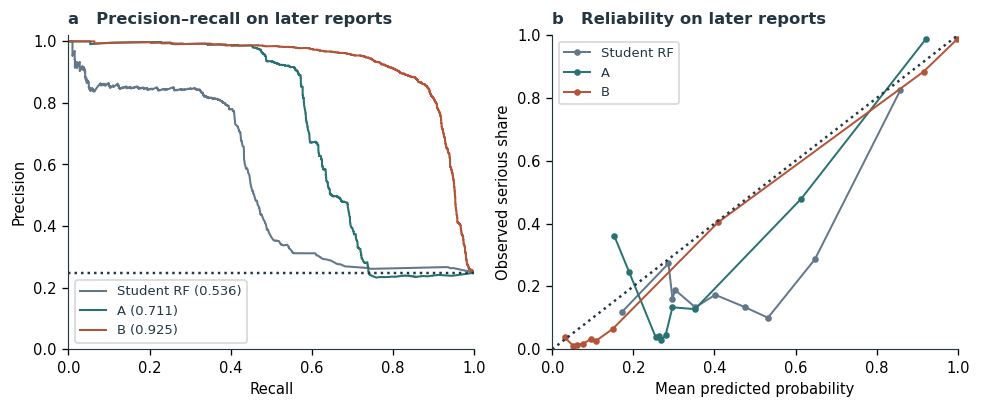

,group,stage,n,positive,prevalence,AP,AUROC,recall,precision
0,semaglutide,A,3180,1771,0.557,0.878,0.797,0.603,0.946
1,semaglutide,B,3180,1771,0.557,0.960,0.941,0.893,0.907
2,tirzepatide,A,4933,243,0.049,0.279,0.680,0.300,0.518
3,tirzepatide,B,4933,243,0.049,0.686,0.933,0.782,0.599


,contrast,delta_AP,low,high,calendar_months,valid_repeats
0,B minus A,0.2138,0.1543,0.2604,14,450
1,B minus Student RF,0.3886,0.3321,0.4238,14,450


In [13]:
def calibration_points(y_true,p):
    t=pd.DataFrame({"truth":y_true,"p":p})
    t["bin"]=pd.qcut(t.p,q=10,duplicates="drop")
    return t.groupby("bin",observed=True).agg(n=("p","size"),forecast=("p","mean"),observed=("truth","mean")).reset_index(drop=True)
fig,(ax,bx)=figure(1,2,3.35); curve_rows=[];cal_rows=[]
for key,color in [("Student RF",COL["neutral"]),("A",COL["base"]),("B",COL["coded"])]:
    pr,rc,_=precision_recall_curve(y[test],scores[key])
    ax.plot(rc,pr,color=color,lw=1.25,label=f"{key} ({average_precision_score(y[test],scores[key]):.3f})")
    curve_rows.append(pd.DataFrame({"model":key,"recall":rc,"precision":pr}))
    z=calibration_points(y[test],scores[key]); z["model"]=key;cal_rows.append(z)
    bx.plot(z.forecast,z.observed,"o-",ms=3,lw=1.2,color=color,label=key)
ax.axhline(y[test].mean(),ls=":",color=COL["ink"]);ax.set(xlabel="Recall",ylabel="Precision",xlim=(0,1),ylim=(0,1.02))
title(ax,"a","Precision–recall on later reports");ax.legend(fontsize=8)
bx.plot([0,1],[0,1],":",color=COL["ink"]);bx.set(xlabel="Mean predicted probability",ylabel="Observed serious share",xlim=(0,1),ylim=(0,1))
title(bx,"b","Reliability on later reports");bx.legend(fontsize=8)
finish(fig,"Fig04_test_curves")
write(pd.concat(curve_rows),"05_pr_curve")
write(pd.concat(cal_rows),"05_reliability")
test_rows=mdl.iloc[test].reset_index(drop=True)
subgroups=[]
for field in ["drug","quarter","sex","age_group","weight_missing"]:
    for group,indices in test_rows.groupby(field).indices.items():
        for s in ["A","B"]:
            subgroups.append(dict(field=field,group=group,stage=s,**metrics(y[test][indices],scores[s][indices],thresholds[s])))
sub=pd.DataFrame(subgroups);write(sub,"05_test_subgroups")
display(sub[sub.field=="drug"][["group","stage","n","positive","prevalence","AP","AUROC","recall","precision"]].round(3))
# 짝지은 월 블록. 월 내부 신고 순서와 두 모델의 대응을 보존한다.
month_id=test_rows.date.dt.to_period("M").astype(str)
calendar=pd.period_range(test_rows.date.min(),test_rows.date.max(),freq="M").astype(str)
blocks=[np.flatnonzero(month_id.to_numpy()==m) for m in calendar]
rng=np.random.default_rng(SEED)
AP=lambda labels,probs:average_precision_score(labels,probs)
diff=[]
for _ in range(450):
    idx=np.concatenate([blocks[k] for k in rng.integers(len(blocks),size=len(blocks))])
    if not len(idx) or np.unique(y[test][idx]).size<2:
        continue
    diff.append([AP(y[test][idx],scores["B"][idx])-AP(y[test][idx],scores[k][idx]) for k in ["A","Student RF"]])
assert diff
boot=[]
for j,k in enumerate(["A","Student RF"]):
    lo,hi=np.quantile(np.asarray(diff)[:,j],[.025,.975])
    boot.append(dict(contrast="B minus "+k,delta_AP=AP(y[test],scores["B"])-AP(y[test],scores[k]),
                     low=lo,high=hi,calendar_months=len(blocks),valid_repeats=len(diff)))
write(pd.DataFrame(boot),"05_paired_month_bootstrap",2)


### XAI | 실제 선정 모델이 어떤 기록 정보에 의존하는가?
**전역 설명**은 시험 데이터에서 하나의 변수군을 신고끼리 함께 섞은 뒤 AP가 얼마나 줄어드는지 측정한다. 예를 들어 반응명과 반응 수를 함께 섞어 같은 신고의 두 정보가 분리되지 않게 한다. 상관된 다른 변수군이 정보를 대신할 수 있어 중요도는 독립적인 인과효과가 아니다. 5회 반복 표준편차는 순열 변동이다.

**개별 설명**은 B의 최종 선정 모델과 확률 보정기를 그대로 사용한다. 시험 날짜순 첫 신고 하나를 미리 정하고, 학습 신고 32개를 고정 배경으로 삼는다. 5개 그룹의 모든 부분집합에 대해 해당 그룹만 사례 값으로 바꾼 예측확률을 평균한다. 이 평균들의 차이를 Shapley 가중치로 합하면 그룹별 기여가 나온다. 배경 평균에 모든 기여를 더하면 해당 신고의 최종 예측확률과 일치해야 한다. 서로 다른 신고의 특성을 섞는 가상 비교라는 점에 유의한다.


,stage,group,delta_AP,repeat_sd,n
0,A,Patient profile,0.0350,0.0022,8113
1,A,Ingredient,-0.0508,0.0013,8113
2,A,Country,0.4596,0.0030,8113
3,A,Reporting time,0.0026,0.0005,8113
4,B,Patient profile,0.0079,0.0006,8113
5,B,Ingredient,-0.0044,0.0002,8113
6,B,Country,0.3144,0.0037,8113
7,B,Reporting time,0.0000,0.0001,8113
8,B,Coded reactions,0.3722,0.0089,8113


,group,contribution,reference_probability,case_probability,reconstruction_error
0,Patient profile,0.1216,0.2258,0.7648,0.0
1,Ingredient,0.0526,0.2258,0.7648,0.0
2,Country,0.1885,0.2258,0.7648,0.0
3,Reporting time,0.0501,0.2258,0.7648,0.0
4,Coded reactions,0.1261,0.2258,0.7648,0.0


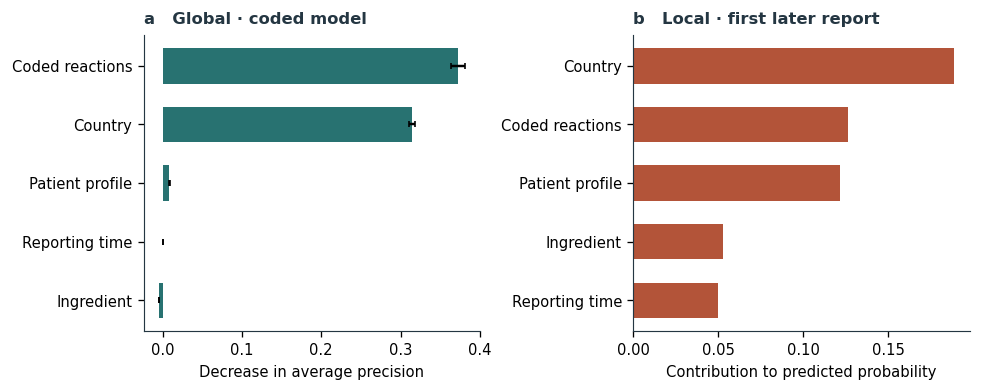

In [14]:
tab_names=[n.split("__",1)[1] for n in namesA]
tags=[]
for n in tab_names:
    if n=="age" or n=="age_missing" or n=="weight" or n=="weight_missing" or n.startswith("sex_"):
        tags.append("Patient profile")
    elif n.startswith("drug_"):
        tags.append("Ingredient")
    elif n.startswith("nation_"):
        tags.append("Country")
    elif n in ["year_num","month_sin","month_cos"]:
        tags.append("Reporting time")
    else:
        raise AssertionError(f"미분류 특징: {n}")
groups=["Patient profile","Ingredient","Country","Reporting time","Coded reactions"]
def group_labels(space):
    extra=matrices[space].shape[1]-len(tags)
    return np.array(tags+["Coded reactions"]*extra)
def parts(key):
    return specs[key] if key.endswith("/blend") else [key]
def replace_groups(space,background,donor,replace):
    # 같은 번호의 행끼리 바꾼다. 원본 행렬을 변경하지 않는다.
    mat=matrices[space]; base=mat[background]; alternate=mat[donor]
    which=np.isin(group_labels(space),list(replace))
    if sparse.issparse(base):
        return (base.multiply(~which)+alternate.multiply(which)).tocsr()
    out=base.copy();out[:,which]=alternate[:,which]
    return out
def hybrid_score(stage,background,donor,replace):
    probs=[]
    for key in parts(winner[stage]):
        space=specs[key]
        xx=replace_groups(space,background,donor,replace)
        probs.append(models[key].predict_proba(xx)[:,1])
    return apply_cal(calibrators[stage],np.mean(probs,axis=0))
pfi=[]
with threadpool_limits(limits=THREADS):
    for st in ["A","B"]:
        origin=AP(y[test],final_p[st])
        for f in (groups if st=="B" else groups[:-1]):
            rng=np.random.default_rng(380)
            ds=[]
            for repeat in range(5):
                p=hybrid_score(st,test,rng.permutation(test),[f])
                ds.append(origin-AP(y[test],p))
            pfi.append(dict(stage=st,group=f,delta_AP=np.mean(ds),repeat_sd=np.std(ds,ddof=1),n=len(test)))
pfi=pd.DataFrame(pfi);write(pfi,"06_group_permutation",10)
background=np.random.default_rng(72).choice(train,size=min(32,len(train)),replace=False)
case=test[0]; donors=np.full(len(background),case)
value={}
with threadpool_limits(limits=THREADS):
    for k in range(len(groups)+1):
        for gset in combinations(groups,k):
            value[frozenset(gset)]=hybrid_score("B",background,donors,gset).mean()
contributions=[]
for group in groups:
    phi=0.
    for subset,score in value.items():
        if group in subset:
            continue
        k=len(subset); weight=factorial(k)*factorial(len(groups)-k-1)/factorial(len(groups))
        phi+=weight*(value[subset|{group}]-score)
    contributions.append(dict(group=group,contribution=phi))
loc=pd.DataFrame(contributions)
base_p=value[frozenset()]
reconstructed=float(base_p+loc.contribution.sum())
assert np.isclose(reconstructed,final_p["B"][0],atol=1e-9)
write(loc.assign(reference_probability=base_p,case_probability=final_p["B"][0],
      reconstruction_error=abs(reconstructed-final_p["B"][0])),"06_local_group_shapley",5)
fig,(ax,bx)=figure(1,2,3.2)
g=pfi[pfi.stage=="B"].sort_values("delta_AP")
ax.barh(g.group,g.delta_AP,xerr=g.repeat_sd,height=.6,color=COL["base"],capsize=2)
title(ax,"a","Global · coded model");ax.set_xlabel("Decrease in average precision")
g=loc.sort_values("contribution");bx.barh(g.group,g.contribution,height=.6,
    color=[COL["coded"] if x>0 else COL["neutral"] for x in g.contribution])
bx.axvline(0,color=COL["ink"],lw=.6);bx.set_xlabel("Contribution to predicted probability")
title(bx,"b","Local · first later report")
finish(fig,"Fig05_model_explanations")


### 민감도 분석 | 국가별 수집 패턴과 반응 명칭의 영향을 분리한다
EDA와 XAI를 보고 설정한 **탐색적 후속 분석**이다. 주 모델의 선택은 바꾸지 않는다. 같은 닫힌 시험에서 반복 비교했으므로 별도 기간에서 재검증할 가설로 다룬다. 첫째, LR의 C를 1로 고정하고 국가 입력 열만 제거해 A·B를 각각 다시 학습한다. 각 모델의 확률 보정과 임계값은 원 검증 뒷기간에서 새로 적합한다. 둘째, 같은 B 모형 규격에서 반응 수만 추가했을 때와 명칭까지 넣었을 때를 비교한다. 셋째, 주 모델을 미국·기타 기재 국가·국가 미상으로 나누어 분모와 성능을 확인한다. 원인·국가별 환자 위험에 대한 추론은 이 비교의 범위 밖이다.


In [15]:
sensitivity=[]
country_index=np.array([t=="Country" for t in tags])
with threadpool_limits(limits=THREADS):
    for label,space,without_country in [("A / LR full",A,False),("A / LR no country",A,True),
                ("A + usable reaction count",B[:,:A.shape[1]+1],False),
                ("B / LR full",B,False),("B / LR no country",B,True)]:
        mask=np.r_[~country_index,np.ones(space.shape[1]-len(tags),dtype=bool)]
        xx=space[:,mask] if without_country else space
        model=LogisticRegression(C=1,solver="liblinear",max_iter=500,random_state=SEED).fit(xx[train],y[train])
        cp=model.predict_proba(xx[cal])[:,1]
        calibrator=fit_cal(cp,y[cal])
        th=f1_threshold(y[cal],apply_cal(calibrator,cp))
        pp=apply_cal(calibrator,model.predict_proba(xx[test])[:,1])
        sensitivity.append(dict(model=label,threshold=th,**metrics(y[test],pp,th)))
write(pd.DataFrame(sensitivity),"06_country_and_reaction_ablation",5)
where=np.select([test_rows.nation=="US",test_rows.nation=="Unknown"],["US","Unknown"],default="Other known")
country_check=[]
for category in ["US","Other known","Unknown"]:
    ix=np.flatnonzero(where==category)
    if len(ix):
        for s in ["A","B"]:
            country_check.append(dict(group=category,stage=s,**metrics(y[test][ix],scores[s][ix],thresholds[s])))
write(pd.DataFrame(country_check),"06_test_by_country_group",6)


,model,threshold,n,positive,prevalence,AP,AUROC,F1,precision,recall,specificity,Brier,accuracy,TP,FP,TN,FN
0,A / LR full,0.4961,8113,2014,0.2482,0.6887,0.6807,0.6934,0.9062,0.5616,0.9808,0.1442,0.8767,1131,117,5982,883
1,A / LR no country,0.3565,8113,2014,0.2482,0.2646,0.4456,0.3711,0.2351,0.8808,0.0536,0.2084,0.2590,1774,5772,327,240
2,A + usable reaction count,0.5185,8113,2014,0.2482,0.7080,0.7132,0.6930,0.9062,0.5611,0.9808,0.1345,0.8766,1130,117,5982,884
3,B / LR full,0.3508,8113,2014,0.2482,0.9250,0.9531,0.8692,0.8593,0.8793,0.9525,0.0539,0.9343,1771,290,5809,243
4,B / LR no country,0.4004,8113,2014,0.2482,0.8441,0.9130,0.7787,0.7764,0.7810,0.9257,0.0860,0.8898,1573,453,5646,441


,group,stage,n,positive,prevalence,AP,AUROC,F1,precision,recall,specificity,Brier,accuracy,TP,FP,TN,FN
0,US,A,6829,863,0.1264,0.1105,0.3539,0.0137,0.4286,0.0070,0.9987,0.1436,0.8733,6,8,5958,857
1,US,B,6829,863,0.1264,0.7890,0.9039,0.7452,0.7662,0.7254,0.9680,0.0522,0.9373,626,191,5775,237
2,Other known,A,930,919,0.9882,0.9942,0.6814,0.9941,0.9882,1.0000,0.0000,0.0186,0.9882,919,11,0,0
3,Other known,B,930,919,0.9882,0.9982,0.8683,0.9941,0.9882,1.0000,0.0000,0.0120,0.9882,919,11,0,0
4,Unknown,A,354,232,0.6554,0.6423,0.4833,0.7742,0.6626,0.9310,0.0984,0.2373,0.6441,216,110,12,16
5,Unknown,B,354,232,0.6554,0.8204,0.7311,0.8278,0.7197,0.9741,0.2787,0.1974,0.7345,226,88,34,6


### 반응명 단위 해석 | 실제 선형 최종 모델이 있을 때만 확인한다
B로 로지스틱 회귀가 선정된 경우에만, 최종 모델의 반응별 계수와 학습·시험 출현 신고 수, 시험에서 그 반응이 있는 신고 중 중대 비율을 연결한다. 계수는 다른 입력이 고정된 상태에서 **반응 표시 열 하나가 더하는 미보정 로그 오즈**다. 반응 수 열의 기여는 별도이다. 희소 용어가 순위를 좌우하지 않도록 학습 신고 50건·시험 신고 20건 이상만 그림에 쓴다. 반복 비교 후 확인한 기술적 설명이며 인과 효과나 처방 지침으로 해석할 수 없다. 다른 데이터에서 트리나 앙상블이 선정되면 위의 공통 XAI가 그대로 적용된다.


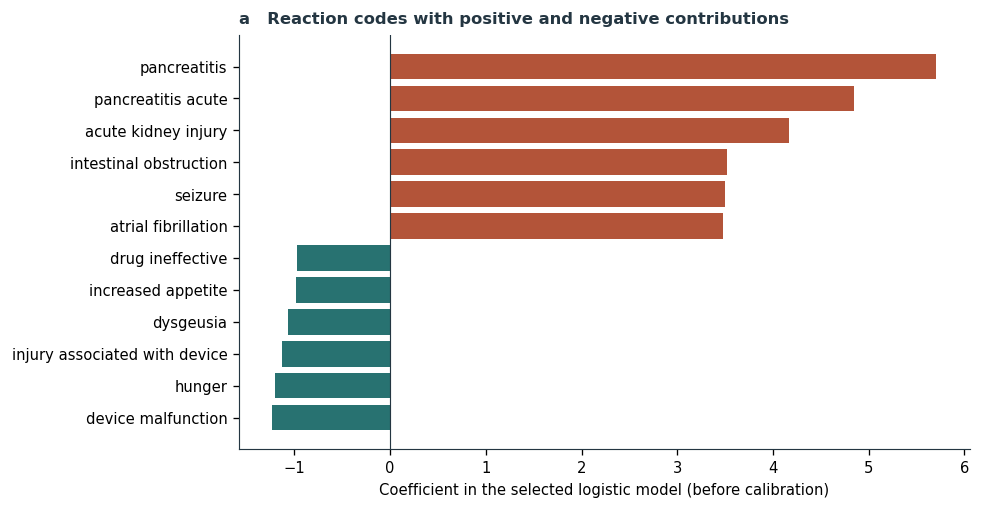

,term,coefficient,train_n,test_n,serious_in_test,test_serious_share,mean_abs_logit_contribution
54,device malfunction,-1.2323,364,20,1,0.0500,0.0030
83,hunger,-1.1993,234,107,6,0.0561,0.0158
173,injury associated with device,-1.1311,103,77,1,0.0130,0.0107
79,dysgeusia,-1.0663,241,27,3,0.1111,0.0035
91,increased appetite,-0.9855,214,91,8,0.0879,0.0111
14,drug ineffective,-0.9702,1287,178,28,0.1573,0.0213
139,atrial fibrillation,3.4796,129,20,20,1.0000,0.0086
229,seizure,3.5000,68,21,20,0.9524,0.0091
267,intestinal obstruction,3.5221,55,31,31,1.0000,0.0135
72,acute kidney injury,4.1704,262,30,30,1.0000,0.0154


In [16]:
if specs[winner["B"]]=="B-linear":
    coef=models[winner["B"]].coef_[0][A.shape[1]+1:]
    test_n=np.asarray(R[test].sum(axis=0)).ravel()
    test_serious=np.asarray(R[test].T @ y[test]).ravel()
    t=pd.DataFrame(dict(term=vocab,coefficient=coef,train_n=[freq[t] for t in vocab],test_n=test_n,
                        serious_in_test=test_serious))
    t["test_serious_share"]=t.serious_in_test/t.test_n.replace(0,np.nan)
    t["mean_abs_logit_contribution"]=t.coefficient.abs()*t.test_n/len(test)
    write(t.sort_values("mean_abs_logit_contribution",ascending=False),"06_term_coefficients")
    supported=t[(t.train_n>=50)&(t.test_n>=20)].sort_values("coefficient")
    if len(supported):
        shown=pd.concat([supported.head(6),supported.tail(6)]).drop_duplicates("term")
        fig,ax=figure(height=4.2)
        ax.barh(shown.term,shown.coefficient,color=[COL["coded"] if v>0 else COL["base"] for v in shown.coefficient])
        ax.axvline(0,color=COL["ink"],lw=.7)
        ax.set_xlabel("Coefficient in the selected logistic model (before calibration)")
        title(ax,"a","Reaction codes with positive and negative contributions")
        finish(fig,"Fig06_reaction_coefficients")
        write(shown,"06_plotted_terms",12)


## 6 · 활용 | 팀이 직접 조작할 수 있는 대시보드
아래 셀은 브라우저에서 열 수 있는 독립형 HTML을 만든다. 약물·연도 범위·국가·성별을 바꾸면 고유 신고 수, 중대 신고 수, 비율, 성분·연도 그래프, 상위 15개 반응이 동시에 바뀐다. 반응별 분모는 해당 필터에서 그 반응을 포함한 신고 수다. 파일에는 필터 계산용 집계값만 담는다. ‘집계표 저장’으로 현재 선택을 CSV로 내보낼 수 있다. 2025년은 1월 17일까지 수록된 부분 연도다.


In [17]:
# 집계 큐브: 필터별 신고 수·중대 건수. 환자/신고 식별자는 HTML에 넣지 않는다.
dashboard_df=reps[[ID,"drug","year","nation","sex","y"]].copy()
dashboard_df["year"]=dashboard_df.year.fillna(-1).astype(int)
dims=["drug","year","nation","sex"]
lookups={field:sorted(dashboard_df[field].unique().tolist()) for field in dims}
for field in dims:
    lookup={v:i for i,v in enumerate(lookups[field])}
    dashboard_df[field]=dashboard_df[field].map(lookup)
grouped=dashboard_df.groupby(dims,as_index=False).y.agg(n="size",s="sum")
termnames=sorted(rx.term.unique())
term_ids={t:i for i,t in enumerate(termnames)}
dash_rx=rx.assign(term=rx.term.map(term_ids)).merge(dashboard_df,on=ID,validate="many_to_one")
rx_counts=dash_rx.groupby(dims+["term"],as_index=False).y.agg(n="size",s="sum")
payload=dict(names=lookups,terms=termnames,reports=grouped.astype(int).values.tolist(),
             events=rx_counts.astype(int).values.tolist())
# JSON 문자열은 HTML 종료 태그와 사용자 입력 문자를 이스케이프한다.
safe_payload=json.dumps(payload,ensure_ascii=False,separators=(",",":")).replace("<","\\u003c").replace(">","\\u003e")
template=r'''<!doctype html>
<html lang="ko"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>GLP-1 이상사례 신고 탐색</title>
<style>
:root{color-scheme:light;--ink:#1d363c;--sub:#50676a;--teal:#1b746b;--line:#cadbd9}
*{box-sizing:border-box}body{margin:0;background:#f4f7f5;color:var(--ink);font:15px/1.55 "Malgun Gothic","Apple SD Gothic Neo",Arial,sans-serif}
main{max-width:1210px;margin:auto;padding:32px 28px}header{padding:23px 27px;background:#e2eeea;border-left:5px solid var(--teal);border-radius:4px}
h1{font-size:clamp(26px,4vw,38px);line-height:1.24;letter-spacing:-.04em;margin:0 0 8px}h2{font-size:19px;line-height:1.3;margin:0 0 14px}p{margin:0;color:var(--sub)}
.filter,.stats,.charts{display:grid;gap:13px;margin-top:20px}.filter{grid-template-columns:repeat(5,minmax(0,1fr)) auto;align-items:end}
label{font-size:13px;font-weight:700}select,button{font:inherit;width:100%;margin-top:5px;padding:8px;background:white;border:1px solid #9ab5af;border-radius:5px;color:var(--ink)}
button{cursor:pointer;padding:8px 15px;font-weight:700}.stats{grid-template-columns:repeat(3,1fr)}.card,section{background:#fff;border:1px solid var(--line);border-radius:8px;padding:16px 19px}
.card span{display:block;font-size:13px;color:var(--sub)}.card strong{font-size:31px;font-variant-numeric:tabular-nums}
.charts{grid-template-columns:1fr 1fr}.bars{display:grid;gap:5px}.bar{display:grid;align-items:center;grid-template-columns:110px 1fr 56px;gap:8px;font-size:13px}
.track{background:#edf3f1;border-radius:3px;min-height:8px}.fill{display:block;height:9px;background:#31877c;border-radius:3px}.bar strong{text-align:right;font-variant-numeric:tabular-nums}
section.wide{margin-top:15px}.top{display:flex;justify-content:space-between;align-items:center;gap:12px}.top button{width:auto;margin:0}
.wrap{overflow:auto}table{width:100%;border-collapse:collapse;font-size:14px;margin-top:8px}th,td{padding:7px 10px;text-align:right;border-bottom:1px solid #e3ecea;font-variant-numeric:tabular-nums}th{background:#f4f8f7}th:first-child,td:first-child{text-align:left}
.note{font-size:13px;margin:12px 0}footer{font-size:12px;color:var(--sub);margin-top:15px}a{color:#166b61}button:focus-visible,select:focus-visible{outline:3px solid #d97c41}
@media(max-width:760px){main{padding:14px}.filter{grid-template-columns:repeat(2,1fr)}.charts{grid-template-columns:1fr}.stats{gap:5px}.card{padding:9px}.card strong{font-size:22px}.bar{grid-template-columns:95px 1fr 50px}.top{align-items:flex-start}.top button{white-space:nowrap;font-size:12px}}
</style><main>
<header><h1>GLP-1 이상사례 신고 탐색</h1><p>성분·기간·국가·성별을 선택해 고유 신고 건수와 신고 내 중대 비율을 비교합니다.</p></header>
<div class="filter"><label>성분<select id="drug"></select></label><label>시작 연도<select id="from"></select></label><label>종료 연도<select id="to"></select></label><label>국가<select id="nation"></select></label><label>성별<select id="sex"></select></label><button id="reset">초기화</button></div>
<div class="stats" aria-live="polite"><div class="card"><span>고유 신고</span><strong id="n"></strong></div><div class="card"><span>중대 신고</span><strong id="s"></strong></div><div class="card"><span>신고 내 중대 비율</span><strong id="rate"></strong></div></div>
<div class="charts"><section><h2>성분별 신고 건수</h2><div id="drugs" class="bars"></div></section><section><h2>연도별 신고 건수</h2><div id="years" class="bars"></div></section></div>
<section class="wide"><div class="top"><h2>선택 집단의 이상사례 상위 15개</h2><button id="save">집계표 저장 (CSV)</button></div><p class="note">반응별 분모는 해당 반응이 포함된 고유 신고입니다. 한 신고에 여러 반응이 들어갈 수 있습니다.</p><div class="wrap"><table><thead><tr><th>보고된 반응</th><th>포함 신고 수</th><th>중대 신고 수</th><th>해당 반응 신고 내 중대 비율</th></tr></thead><tbody id="body"></tbody></table></div></section>
<footer>‘Unknown’은 정보 미상입니다. 연도 필터를 지정하면 날짜 미상은 제외합니다. 양 끝 연도는 부분 연도일 수 있습니다. 투약자 전체에 대한 발생률과 인과성을 추정할 수 없습니다. <a href="https://open.fda.gov/apis/drug/event/">FDA 보고자료 설명</a></footer>
</main><script type="application/json" id="data">__DATA__</script><script>
'use strict';
const D=JSON.parse(document.querySelector('#data').textContent),q=id=>document.getElementById(id),fmt=new Intl.NumberFormat('ko-KR');
const option=(el,value,label)=>{let o=document.createElement('option');o.value=value;o.textContent=label;el.append(o)};
for(const k of ['drug','nation','sex']){option(q(k),'','전체');D.names[k].forEach((v,i)=>option(q(k),i,v))}
for(const k of ['from','to']){option(q(k),'','전체');D.names.year.filter(v=>v>=0).forEach(v=>option(q(k),v,v))}
let termRows=[],chosenRows=[];
function update(trigger){
 let lo=q('from').value,hi=q('to').value;
 if(lo&&hi&&Number(lo)>Number(hi)){if(trigger==='from')q('to').value=hi=lo;else q('from').value=lo=hi}
 const values=['drug','nation','sex'].map(k=>q(k).value);
 const pass=r=>(values[0]===''||r[0]===+values[0])&&(values[1]===''||r[2]===+values[1])&&(values[2]===''||r[3]===+values[2])&&
    ((!lo&&!hi)||(D.names.year[r[1]]>=0&&(!lo||D.names.year[r[1]]>=+lo)&&(!hi||D.names.year[r[1]]<=+hi)));
 const m=new Map(), yrs=new Map(),ts=new Map();let n=0,s=0;chosenRows=[];
 for(const r of D.reports){if(!pass(r))continue;n+=r[4];s+=r[5];
   const name=D.names.drug[r[0]],year=D.names.year[r[1]];m.set(name,(m.get(name)||0)+r[4]);yrs.set(year,(yrs.get(year)||0)+r[4]);}
 for(const r of D.events){if(!pass(r))continue;const i=r[4],v=ts.get(i)||[0,0];v[0]+=r[5];v[1]+=r[6];ts.set(i,v)}
 q('n').textContent=fmt.format(n);q('s').textContent=fmt.format(s);q('rate').textContent=n?(100*s/n).toFixed(1)+'%':'—';
 function bars(id,arr){
  let el=q(id);el.replaceChildren();if(!arr.length){el.textContent='조건에 맞는 신고가 없습니다.';return}
  let max=Math.max(...arr.map(row=>row[1]));for(const [label,count] of arr){
   let row=document.createElement('div'),name=document.createElement('span'),track=document.createElement('span'),fill=document.createElement('span'),amount=document.createElement('strong');
   row.className='bar';track.className='track';fill.className='fill';fill.style.width=(100*count/max)+'%';name.textContent=label;amount.textContent=fmt.format(count);track.append(fill);row.append(name,track,amount);el.append(row)
  }
 }
 bars('drugs',[...m].sort((a,b)=>b[1]-a[1]));bars('years',[...yrs].sort((a,b)=>a[0]-b[0]).map(([v,n])=>[v<0?'미상':v,n]));
 let tbody=q('body');tbody.replaceChildren();termRows=[...ts].map(([i,[nr,sr]])=>[D.terms[i],nr,sr,sr/nr]);
 termRows.sort((a,b)=>b[1]-a[1]||a[0].localeCompare(b[0],'en'));
 for(const [t,nr,sr,rt] of termRows.slice(0,15)){
  let tr=document.createElement('tr');[t,fmt.format(nr),fmt.format(sr),(100*rt).toFixed(1)+'%'].forEach(x=>{let td=document.createElement('td');td.textContent=x;tr.append(td)});tbody.append(tr)
 }
 if(!termRows.length){let tr=tbody.insertRow(),c=tr.insertCell();c.colSpan=4;c.textContent='표시할 반응이 없습니다.'}
 chosenRows=[['drug','from_year','to_year','country','sex','term','reports','serious','serious_share'],
 ...termRows.map(row=>[...['drug','from','to','nation','sex'].map(k=>q(k).selectedOptions[0].text),...row])];
}
for(const k of ['drug','from','to','nation','sex'])q(k).onchange=()=>update(k);
q('reset').onclick=()=>{for(const k of ['drug','from','to','nation','sex'])q(k).value='';update()};
q('save').onclick=()=>{const clean=x=>'"'+String(x).replace(/"/g,'""')+'"';let t=chosenRows.map(r=>r.map(clean).join(',')).join('\r\n');
 const a=document.createElement('a');a.href=URL.createObjectURL(new Blob(['\ufeff'+t],{type:'text/csv;charset=utf-8'}));a.download='GLP1_filtered_reactions.csv';a.click();setTimeout(()=>URL.revokeObjectURL(a.href),1500);};update();
</script></html>
'''
dashboard=OUT/"GLP1_Interactive_Dashboard.html"
dashboard.write_text(template.replace("__DATA__",safe_payload),encoding="utf-8")
print(f"대시보드 생성: {dashboard.name} · 결과 ZIP에서 이 파일을 꺼내 브라우저로 여세요.")


대시보드 생성: GLP1_Interactive_Dashboard.html · 결과 ZIP에서 이 파일을 꺼내 브라우저로 여세요.


### 배포본 해설 | 학생들이 발표에서 확인할 세 가지

아래 수치는 첨부 원자료로 실행한 예시다. 다른 자료로 실행할 때에는 위에서 새로 출력한 결과표를 사용한다.

1. **학생 전처리는 대부분 재현됐다.** 신고 ID, 중대 라벨, 나이에는 차이가 없었고, 체중 처리만 1건 달랐다. 1.7kg을 검토 표시와 함께 보존했다. 원본의 87,075kg은 결측으로 처리했다. 전체 54,170건 중 중대 신고는 15,502건이고, 이 가운데 7,957건은 제공된 네 가지 중대성 플래그가 모두 꺼져 있다.
2. **국가 구성이 전체 점수를 크게 바꿨다.** 기본정보 모델의 시험 AUROC는 전체 0.718이었으나, 미국 신고 6,829건 안에서는 0.354였다. 같은 시험 기간에 미국 신고 6,829건 중 863건, 미국 외 국가가 기재된 신고 930건 중 919건이 중대였다. 이는 수집된 신고의 구성 차이다. 국가별 환자 위험 차이로 해석할 수 없다.
3. **반응 코딩이 제공된 시점의 과제에서 성능이 좋아졌다.** 선정된 B의 시험 AP는 0.925, F1은 0.868이었다. 로지스틱 회귀 규제 강도를 고정한 추가 비교에서 반응 수만 사용한 경우 AP는 0.708, 개별 반응명까지 쓴 경우 0.925였다. B에서 국가 열을 제외하고 다시 학습해도 AP는 0.844였다. 정보가 아직 코딩되지 않은 실시간 접수 단계로 이 성능을 옮겨 쓸 수 없다.

발표에서는 Fig01로 관측 집단을 먼저 소개하고, Fig04와 국가별 시험표로 전체 점수의 범위를 설명한 다음 Fig05–06으로 모델이 어떤 기록에 의존했는지 연결한다.


### 팀별 논문 시나리오 | 표와 그림에서 주장 범위를 정한다

| 방향 | 선택 조건과 질문 | 발표에 넣을 근거 | 다음 검증 |
|---|---|---|---|
| ① 보고 구성의 이동 | 초기와 말기 자료의 성분 구성이 얼마나 달라졌나? | Fig01, 03_drug_shift, 브랜드별 서로 다른 신고 수. 조회명별 수집 규모가 비슷한지 점검 | 원 제공자의 추출 조건 또는 독립 기간에서 재확인 |
| ② 기록 시점과 예측력 | 접수 기본정보와 코딩 완료 정보 사이의 성능 차이는? | 같은 신고의 A/B AP·ROC-AUC, 짝지은 월 블록 구간, Fig04 | 시간 표시가 있는 독립 신고에서 실제 사용 시점 검증 |
| ③ 전체 성능 vs. 성분별 성능 | 전체에서 좋아진 점수가 두 시험 성분에서도 유지되는가? | 05_test_subgroups의 표본·양성 수·AP·양성률·Recall. 각 성분의 AP는 해당 양성률과 비교 | 다른 성분 또는 수집 기간 외부 검증 |
| ④ 기록 누락과 중대 분류 | 체중 미기재 집단에서 모델의 성능·설명이 달라지나? | 02_missing, 05_test_subgroups, Fig05. 결측이 기록 관행을 대변할 가능성 | 다른 보고기관이나 수집 방식에서 재검증 |
| ⑤ 통계·시각화 중심 | 예측이 약해도 통계로 설명할 수 있는 패턴은? | Fig02–03, 반응 TOP 15, 분모와 Wilson 구간, 성별 연관의 Cramér’s V | 희귀 성분·소수 집단은 수치와 불확실성만 기술 |

**어디까지 말할 수 있나?**　공개본의 시험 기간에 포함되지 않은 성분의 성능, 개별 약물의 상대적 안전성, 환자 치료 선택까지 확대할 수 없다. 작은 신고 비율 차이의 p값만 강조하기보다 구간·분모·연도 범위를 함께 쓴다. 독립 검증 전에는 ‘신고의 중대 표식 분류’로 연구 제목과 결론을 맞춘다.

**내보내기**　학생이 바꾼 그림을 저장하려면 해당 그림 셀과 마지막 셀을 다시 실행한다. 결과 ZIP에 정제한 두 표, 제외·충돌 내역, 평가·XAI의 원 수치, 고해상도 그림과 대시보드가 들어간다.


In [18]:
manifest=dict(input_filename=path.name,input_type=input_mode,input_sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
             seed=SEED,dimensions=dict(reports=len(reps),terms=len(rx)),chosen=winner,chosen_spec=specs,
             train_through="2022-07-14",validation_through="2023-12-29",calibration_from=str(cut.date()),
             splits={name:len(ids) for name,ids in [("train",train),("selection",select),("calibration",cal),("test",test)]},
             thresholds=thresholds,dpi=DPI,weight_rule_kg="0 < weight <= 500",age_rule_yr="0 <= age <= 120",
             min_term_reports=5,tree_term_cap=K,proxy_exclusion_regex=OUTCOME_PATTERN,bootstrap_repeats=450,
             local_xai_error=abs(reconstructed-final_p["B"][0]),python=platform.python_version(),
             packages={x:version(x) for x in ["pandas","numpy","scipy","scikit-learn","matplotlib","openpyxl"]},
             elapsed_seconds=round(time.monotonic()-START,1))
(OUT/"run_info.json").write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding="utf-8")
howto="""GLP-1 이상사례 PBL 수업 결과
GLP1_Interactive_Dashboard.html — 압축을 모두 풀고 브라우저에서 열기. 필터 변경 및 집계 CSV 내보내기.
clean_data/ — 재구성한 신고표와 반응표(CSV.GZ). 두 표의 공통 키는 safetyreportid.
figures/ — 각 그림에 600 dpi PNG·PDF·SVG. B가 선형 모형이면 반응명 계수 그림도 출력.
tables/01* — 정제·품질 감사. 02* — EDA. 03* — 기간·어휘·구성. 04* — 검증과 보정. 05* — 시간 시험. 06* — 최종 모델 설명.
run_info.json — 입력 해시, 기간, 모델, 임계값, 패키지 버전.
회고적 신고 분류 실험. 각 성분·환자군의 투약 인원 분모는 제공되지 않음.
"""
(OUT/"README_ko.txt").write_text(howto,encoding="utf-8")
bundle=shutil.make_archive(str(OUT),"zip",OUT)
summary=test_table[test_table.rule!="fixed 0.5"][["model","n","AP","AUROC","F1","recall","precision","Brier"]]
display(summary.round(4))
print("출력 파일",Path(bundle).name)
if AUTO_DOWNLOAD:
    try:
        from google.colab import files
    except ImportError:
        print("로컬 환경에서는 출력 폴더의 ZIP을 여세요.")
    else:
        files.download(bundle)


,model,n,AP,AUROC,F1,recall,precision,Brier
0,Prevalence,8113,0.2482,0.5000,0.0000,0.0000,0.0000,0.1893
1,Student RF,8113,0.5364,0.6530,0.4425,0.4866,0.4058,0.1985
2,A,8113,0.7112,0.7180,0.6949,0.5665,0.8984,0.1333
4,B,8113,0.9250,0.9531,0.8692,0.8793,0.8593,0.0539


출력 파일 GLP1_PBL_t_tpfqwa.zip
